# Landsat project PBL 1 PBL 2 and PBL 3

This notebook demonstrates the requested course methods on the same ten Landsat 8 inputs as the app.
Run from the repository root using its pinned requirements. Download and prepare the Drive data first.
On Colab, clone the public repository, install requirements appropriate for that runtime, mount Drive,
copy the supplied files and parts into colab_test_data, and run prepare_data.py. Set LANDSAT_DATA_DIR if needed.

The two acquisition dates are 2015-12-13 and 2024-07-30. No independent land-cover labels exist.
All supervised scores below are agreement with provisional spectral-rule labels.


In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from landsat_analysis import discover, analyze
from pbl_analysis import (load_course_data, fit_unsupervised, run_temporal,
                          fit_supervised, sum_product, transition_matrix)
from build_pbl_demo import save_course_results

ROOT = Path.cwd()
DATA_DIR = Path(os.environ.get('LANDSAT_DATA_DIR', str(ROOT / 'colab_test_data')))
assert DATA_DIR.is_dir(), 'Download the Drive data and run prepare_data.py first.'
OUTPUT = ROOT / 'outputs' / 'pbl'


## PBL 1 Existing baseline

Use surface-reflectance scaling, QA masking and nearest-neighbor alignment, then demonstrate provisional
maximum-likelihood classification and per-band linear regression. The robust residual threshold flags
possible spectral change. This maps PBL 1 to the existing project; confirm the formal PBL 1 assignment.


In [2]:
acquisitions = sorted(discover(str(DATA_DIR)).values(), key=lambda a: a.date)
baseline = analyze(acquisitions[0], acquisitions[1])
display(pd.DataFrame(baseline['report']['regression']['bands']).T)
display(baseline['report']['change_classification'])
del baseline  # Release the baseline display arrays before the course methods.


          slope  intercept  r2_sample  rmse_all
SR_B2  0.544376   0.020600   0.067373  0.035217
SR_B3  0.551667   0.047247   0.072011  0.037559
SR_B4  0.576621   0.028756   0.116726  0.046372
SR_B5  0.316996   0.281362   0.025582  0.089639

{'status': 'Possible spectral change; not verified land-cover change', 'method': 'median + 3 x 1.4826 x MAD of standardized residual scores', 'threshold': 3.008498520863056, 'possible_change_pixels': 33167, 'unchanged_pixels': 599221, 'possible_change_percent': 5.244723176277855}

## Shared data and spatial evaluation design

The eastern quarter of common valid Before pixels is held out, with an eight-column guard strip.
Training-area pixels alone determine all fitted preprocessing and spectral-rule thresholds.
After is a separate, unvalidated transfer visualization; it is not a labelled test set.


In [3]:
data = load_course_data(DATA_DIR)
display(data['split'])
print('Common valid pixels:', int(data['common'].sum()))


Common valid pixels: 632388


{'test_column_start': 846, 'buffer_pixels': 8, 'training_pixels': 469452, 'test_pixels': 158536, 'excluded_guard_pixels': 4400, 'method': 'Eastern quarter spatial holdout; eight-column guard strip'}

## PBL 2 K-means clustering and PCA

Fit StandardScaler, KMeans(k=4, n_init=10) and full four-component PCA on a fixed sample of up to
20,000 Before training pixels. Reuse the centroids on both dates. Plot PC1 and PC2 without dropping
the other bands from the K-means or HMM models. Cluster IDs are arbitrary, not supervised class names.


In [4]:
unsupervised = fit_unsupervised(data)
display(pd.DataFrame(unsupervised['report']['centroids_reflectance'], columns=['B2', 'B3', 'B4', 'B5']))
variance = np.array(unsupervised['report']['pca_explained_variance_ratio'])
display(pd.DataFrame({'Component': range(1, 5), 'Variance ratio': variance, 'Cumulative': variance.cumsum()}))


         B2        B3        B4        B5
0  0.065099  0.097152  0.103568  0.196397
1  0.044676  0.082473  0.068575  0.287608
2  0.044335  0.074781  0.068374  0.195502
3  0.085905  0.121570  0.138872  0.211253

   Component  Variance ratio  Cumulative
0          1        0.729221    0.729221
1          2        0.250698    0.979918
2          3        0.013016    0.992934
3          4        0.007066    1.000000

## PBL 2 Hidden Markov model

For each pixel, z1 and z2 are hidden spectral states and x1 and x2 are observed four-band spectra.
The factorization is p(z1,z2,x1,x2) = pi(z1) e1(x1|z1) A(z1,z2) e2(x2|z2).
Initial frequencies and diagonal-Gaussian emissions come from the Before training clusters.
The transition prior assumes 0.90 same-state persistence over the entire nine-year interval.
Two dates support inference but do not identify a reliable learned transition model.


In [5]:
temporal = run_temporal(data, unsupervised, persistence=0.90)
display(pd.DataFrame(temporal['report']['transition']))
display(pd.DataFrame(temporal['report']['expected_transition_counts']))


          0         1         2         3
0  0.900000  0.033333  0.033333  0.033333
1  0.033333  0.900000  0.033333  0.033333
2  0.033333  0.033333  0.900000  0.033333
3  0.033333  0.033333  0.033333  0.900000

              0              1             2             3
0  27885.429675  125439.532744  16384.889814  45659.193748
1   1971.583201  160169.431221   1747.371956  14987.822028
2   3418.087265   64279.738869  28960.695458  16839.063323
3   4041.760162   46762.166589   8008.523675  65832.710272

## PBL 2 Sum-product algorithm

Forward-backward is exact sum-product on the HMM chain. Local factors are multiplied and hidden
states are summed out. The implementation uses scipy.special.logsumexp for numerical stability.
The state and adjacent-state marginals must each normalize to one. This is not Viterbi decoding.
Change the assumed persistence below to explore sensitivity for one actual pixel.


In [6]:
example = temporal['report']['examples'][2]
persistence = 0.90
posterior, joint, log_evidence = sum_product(
    np.array(example['log_emissions'])[None], temporal['report']['initial'],
    transition_matrix(4, persistence))
display(pd.DataFrame(posterior[0], index=data['dates'], columns=[f'State {i}' for i in range(4)]))
display(pd.DataFrame(joint[0, 0]))
print('Posterior of different latent states:', float(1 - np.trace(joint[0, 0])))
np.testing.assert_allclose(posterior.sum(axis=2), 1, atol=1e-10)
np.testing.assert_allclose(joint.sum(axis=(2, 3)), 1, atol=1e-10)


Posterior of different latent states: 0.638352095982931


                 State 0   State 1   State 2       State 3
2015-12-13  6.286707e-01  0.042951  0.328343  3.446088e-05
2024-07-30  6.588246e-19  0.130558  0.869442  5.237408e-16

              0         1         2             3
0  6.579302e-19  0.093050  0.535620  5.045036e-16
1  3.433856e-22  0.035404  0.007548  7.109358e-18
2  5.497156e-22  0.002099  0.326244  1.138116e-17
3  1.335732e-24  0.000005  0.000029  7.466743e-19

## PBL 3 CART Boosting and Ensemble Learning

Use four reflectance bands plus NDVI and NDWI. Spectral-rule labels use thresholds derived only
from the training area. Exclude pixels that match zero or multiple rules. CART uses Gini splits
and depth 6. AdaBoost uses 80 depth-one trees. Random forest uses 80 bootstrapped randomized trees.
Soft voting equally averages their probability outputs. Settings are fixed before evaluation.


In [7]:
supervised = fit_supervised(data)
display(pd.DataFrame([{k:v for k,v in m.items() if k != 'confusion_matrix'}
                      for m in supervised['report']['metrics']]))
display(supervised['report']['sample_class_counts'])
print(supervised['report']['note'])


Scores are agreement with provisional spectral rules, not independent land-cover accuracy. Only unique rule matches are evaluated. Thresholds and models fit Before training area only. Eastern Before holdout is evaluation; After maps are unvalidated transfer predictions. Do not choose hyperparameters using the displayed holdout round curve.


           model  rule_agreement  macro_f1  balanced_rule_agreement
0           CART        0.999667  0.999773                 0.999804
1       AdaBoost        0.661500  0.423105                 0.500000
2  Random forest        0.999583  0.999102                 0.999755
3    Soft voting        0.999667  0.999773                 0.999804

{'training': [4000, 4000, 4000, 4000], 'holdout': [193, 3869, 2827, 5111]}

## Save and inspect all figures

This cell writes course_results.json, model_comparison.csv, CART rules and all course figures.
The Streamlit Course demo opens these saved artifacts without retraining.


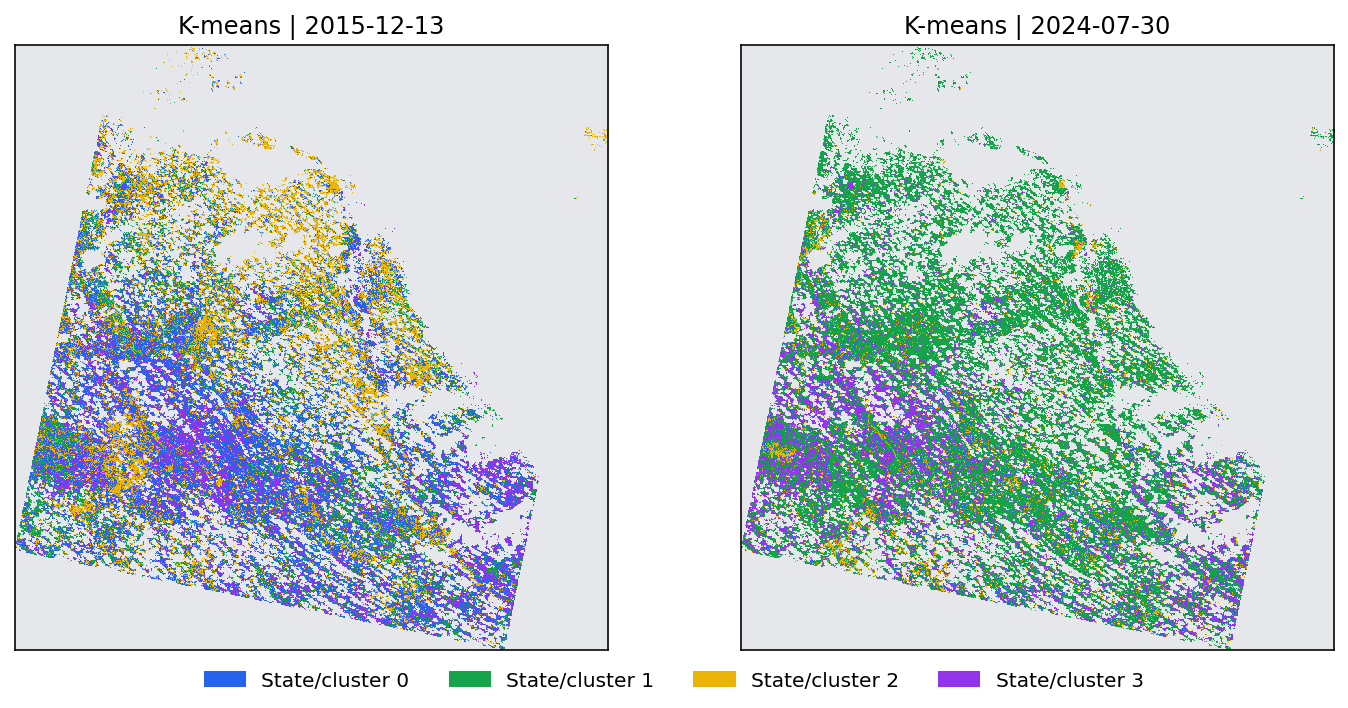

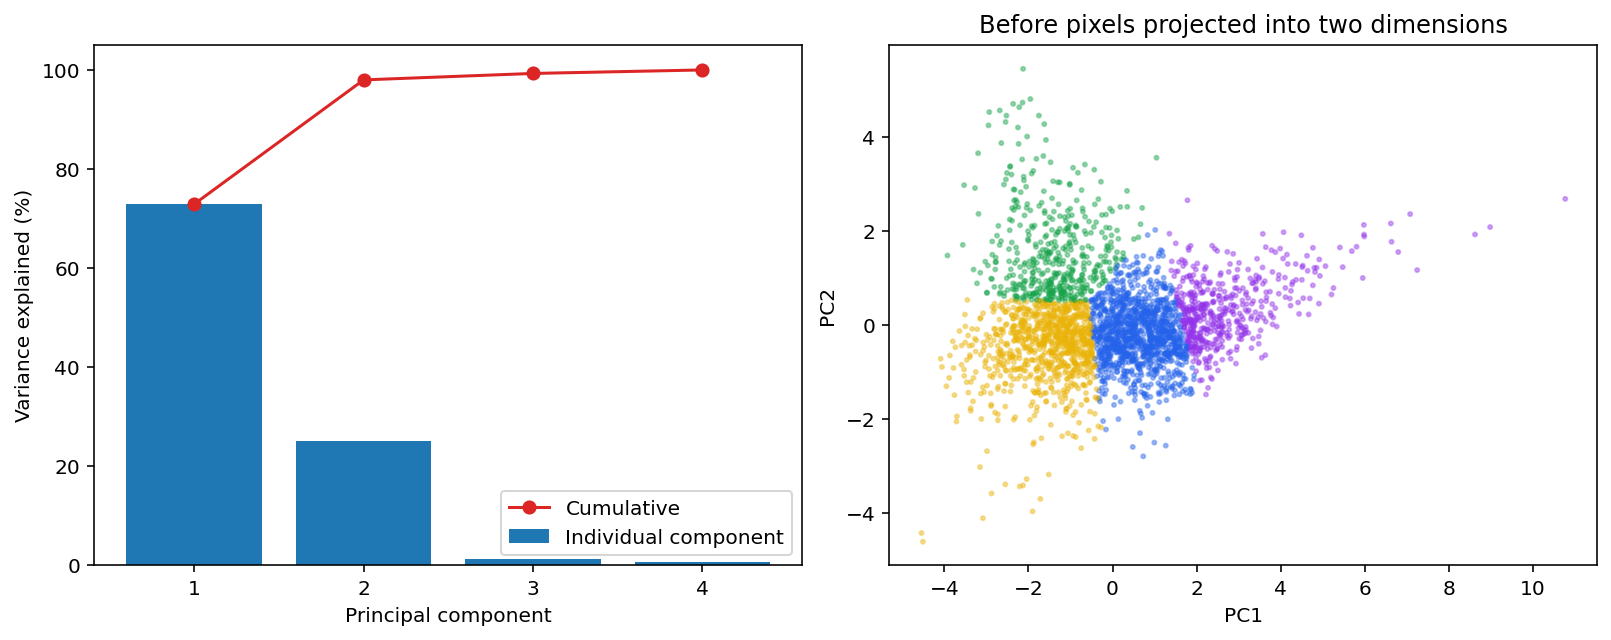

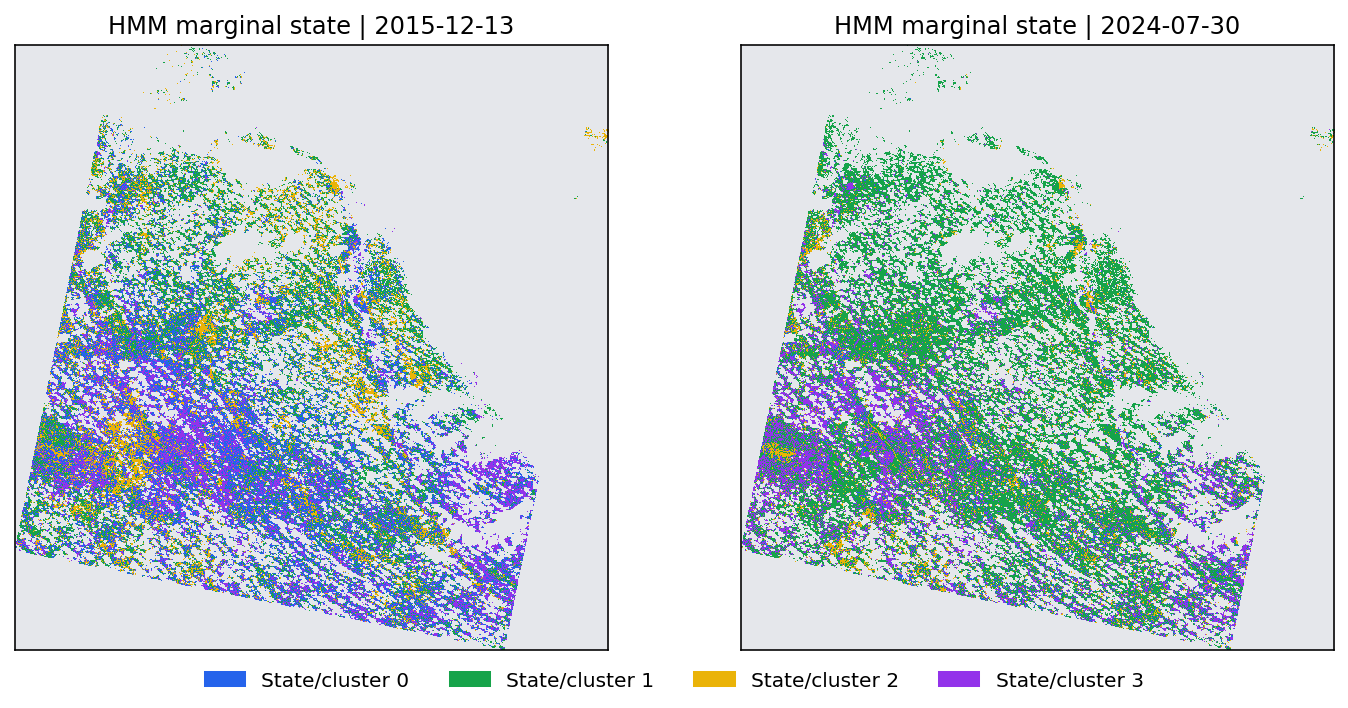

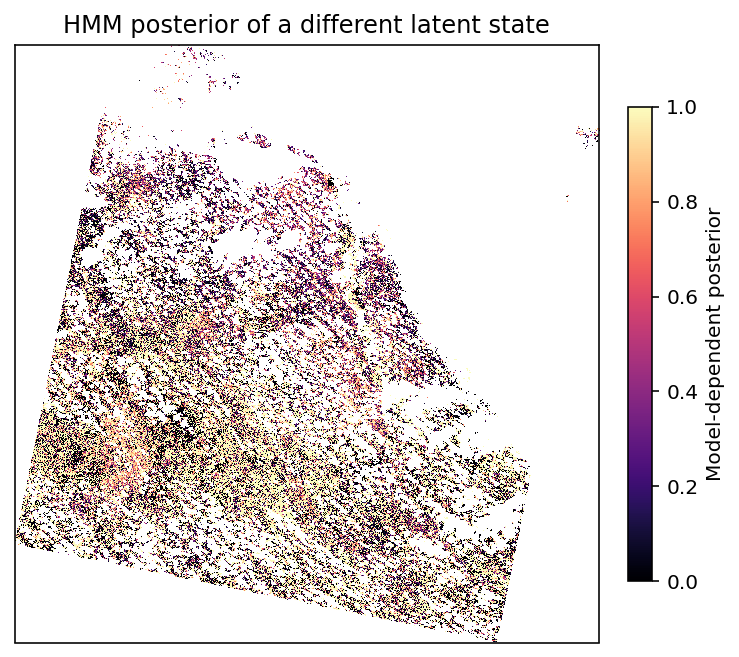

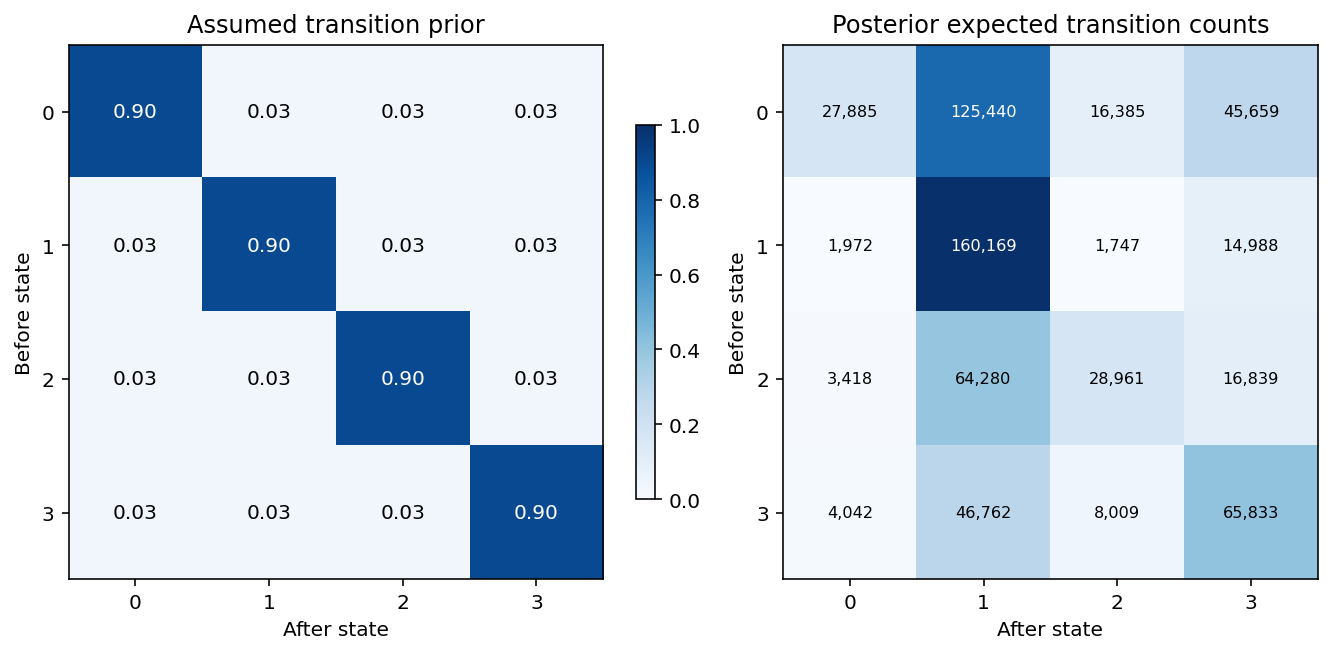

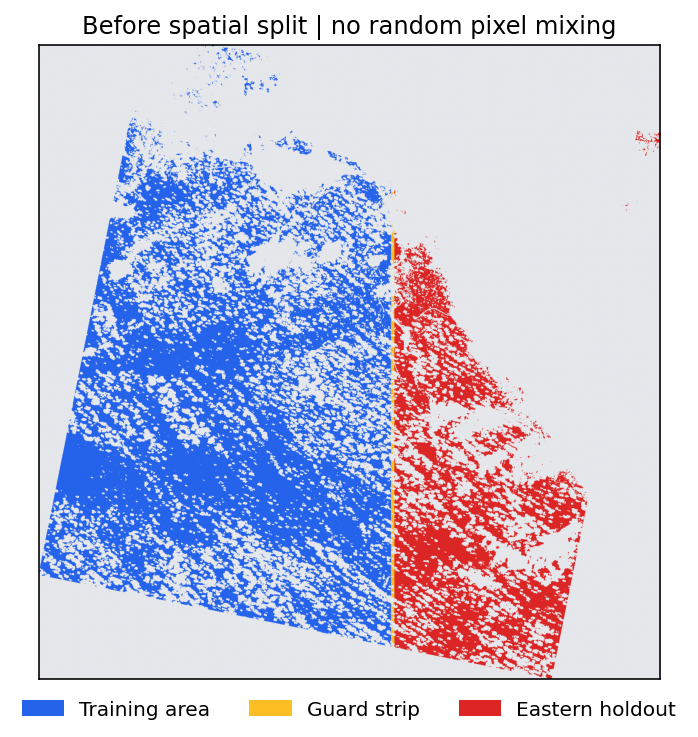

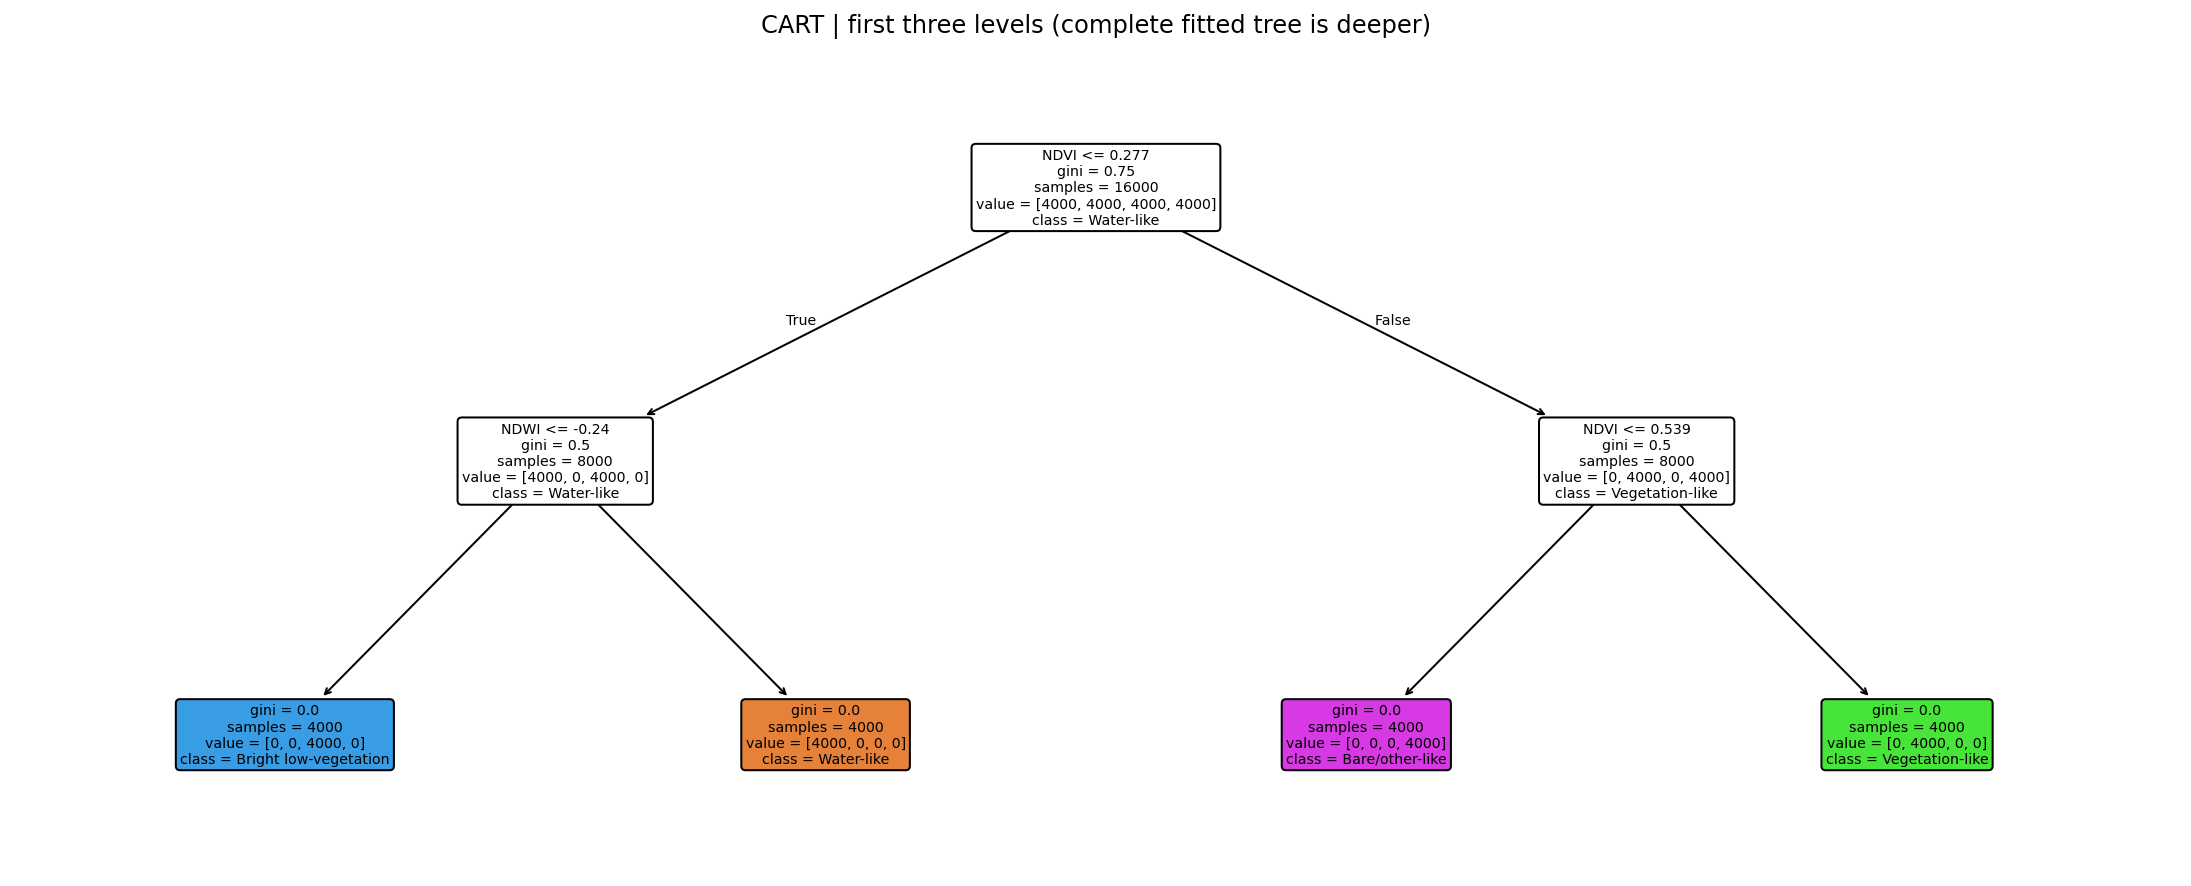

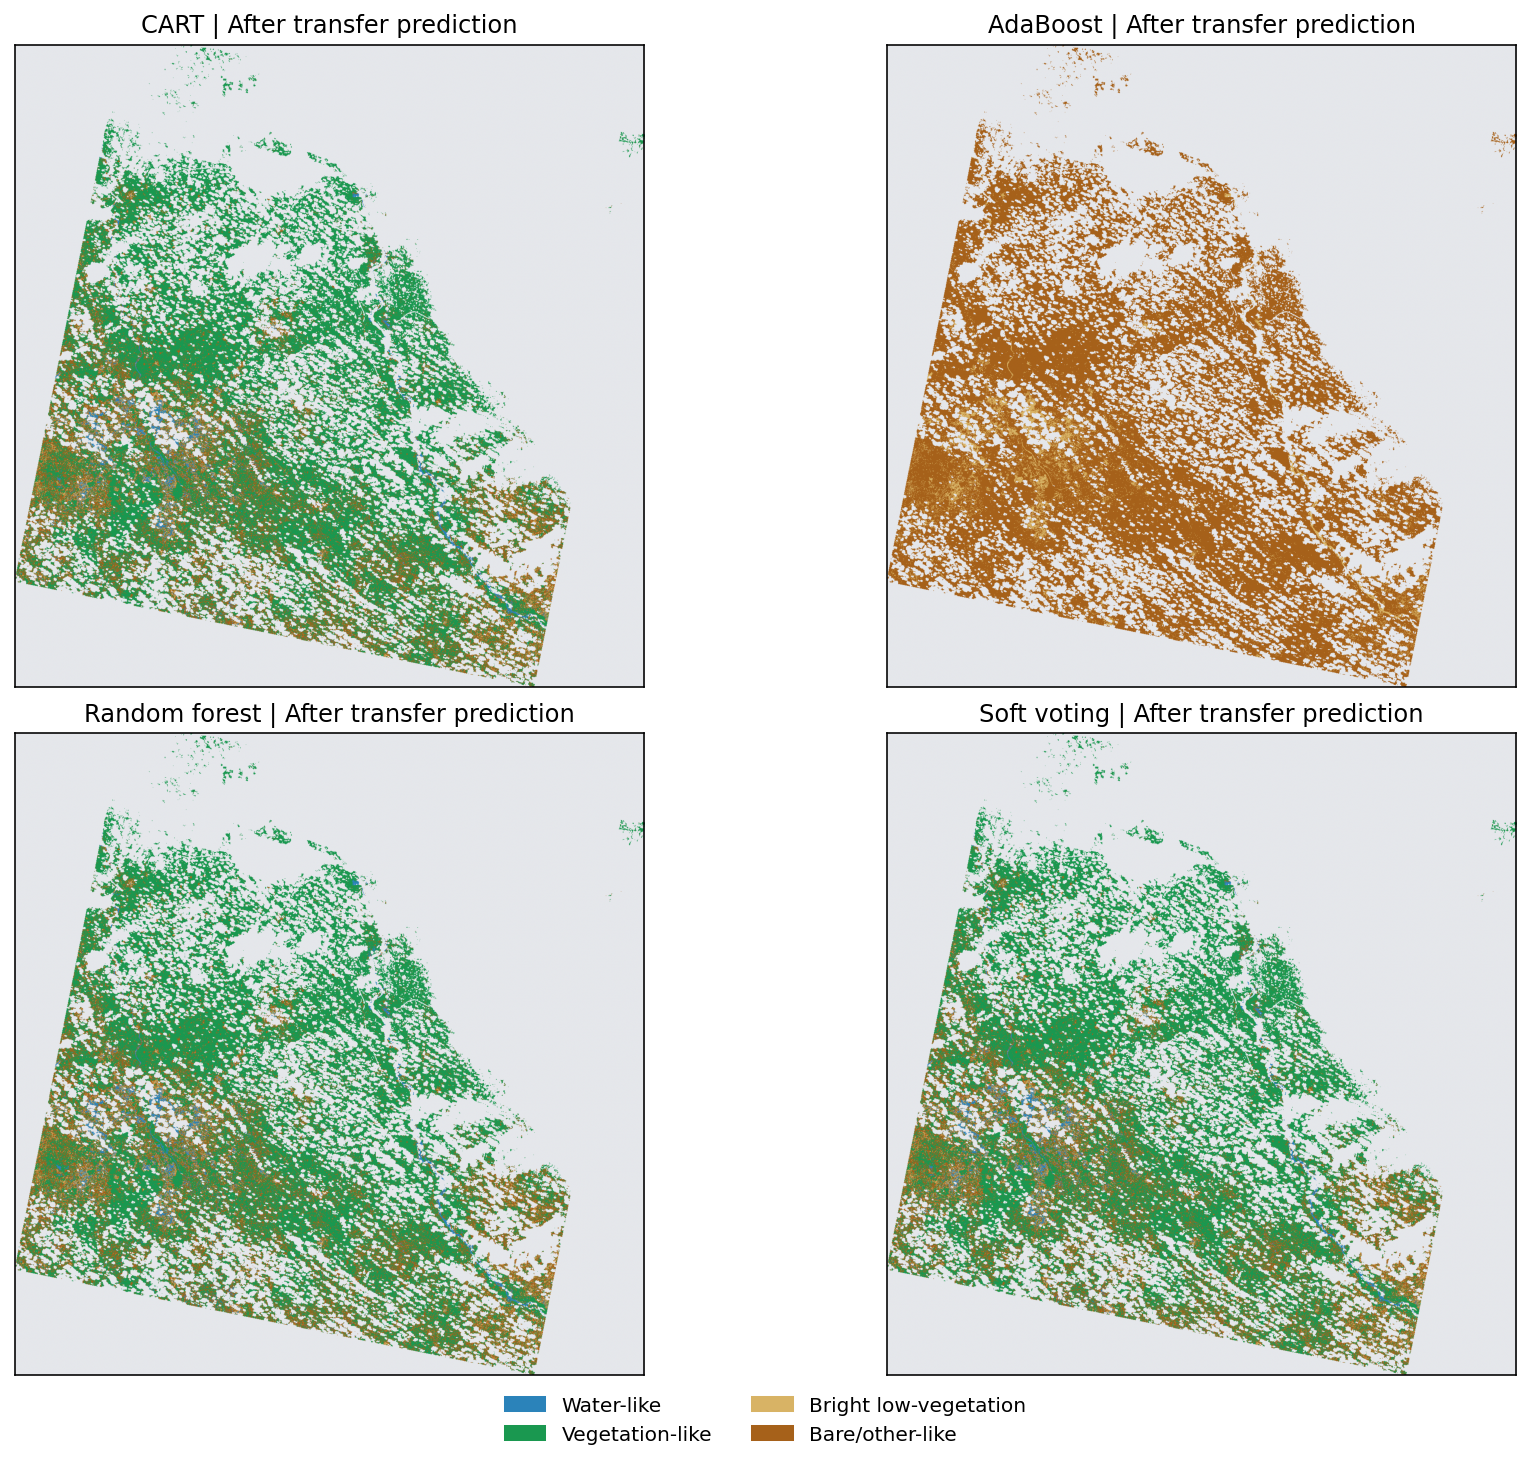

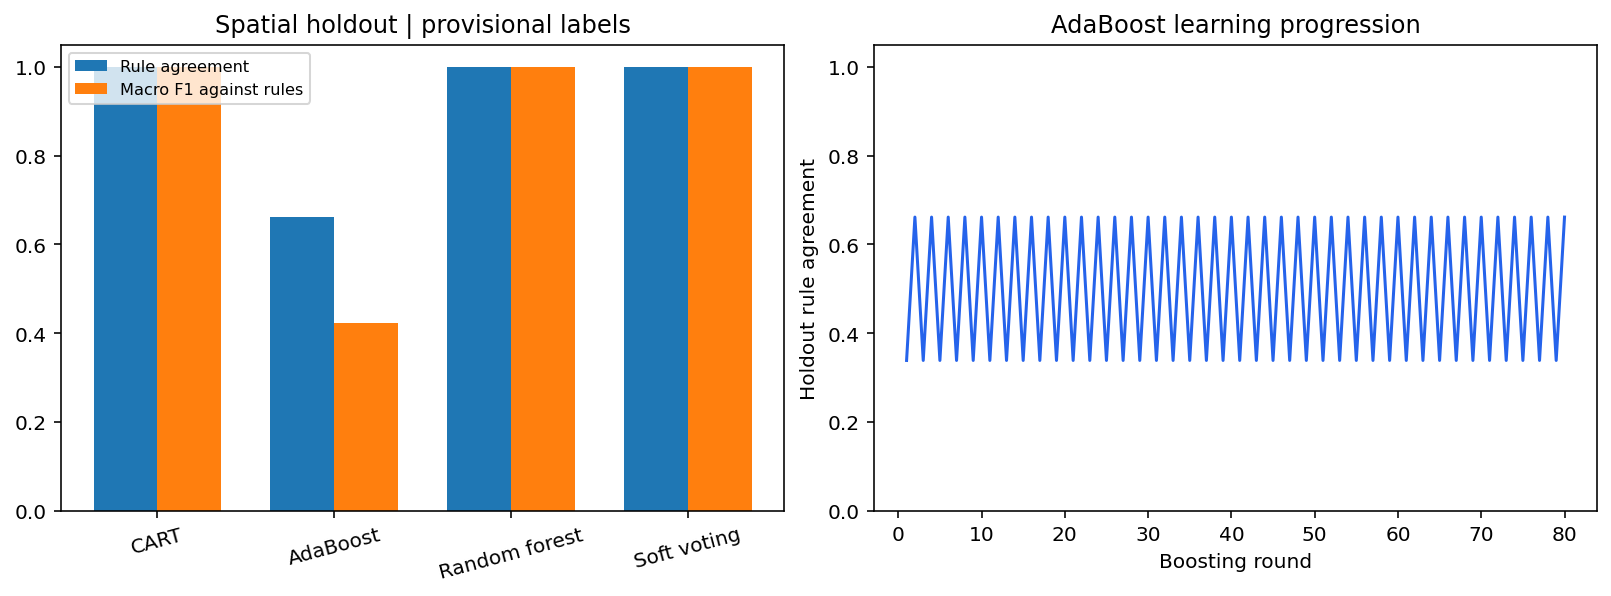

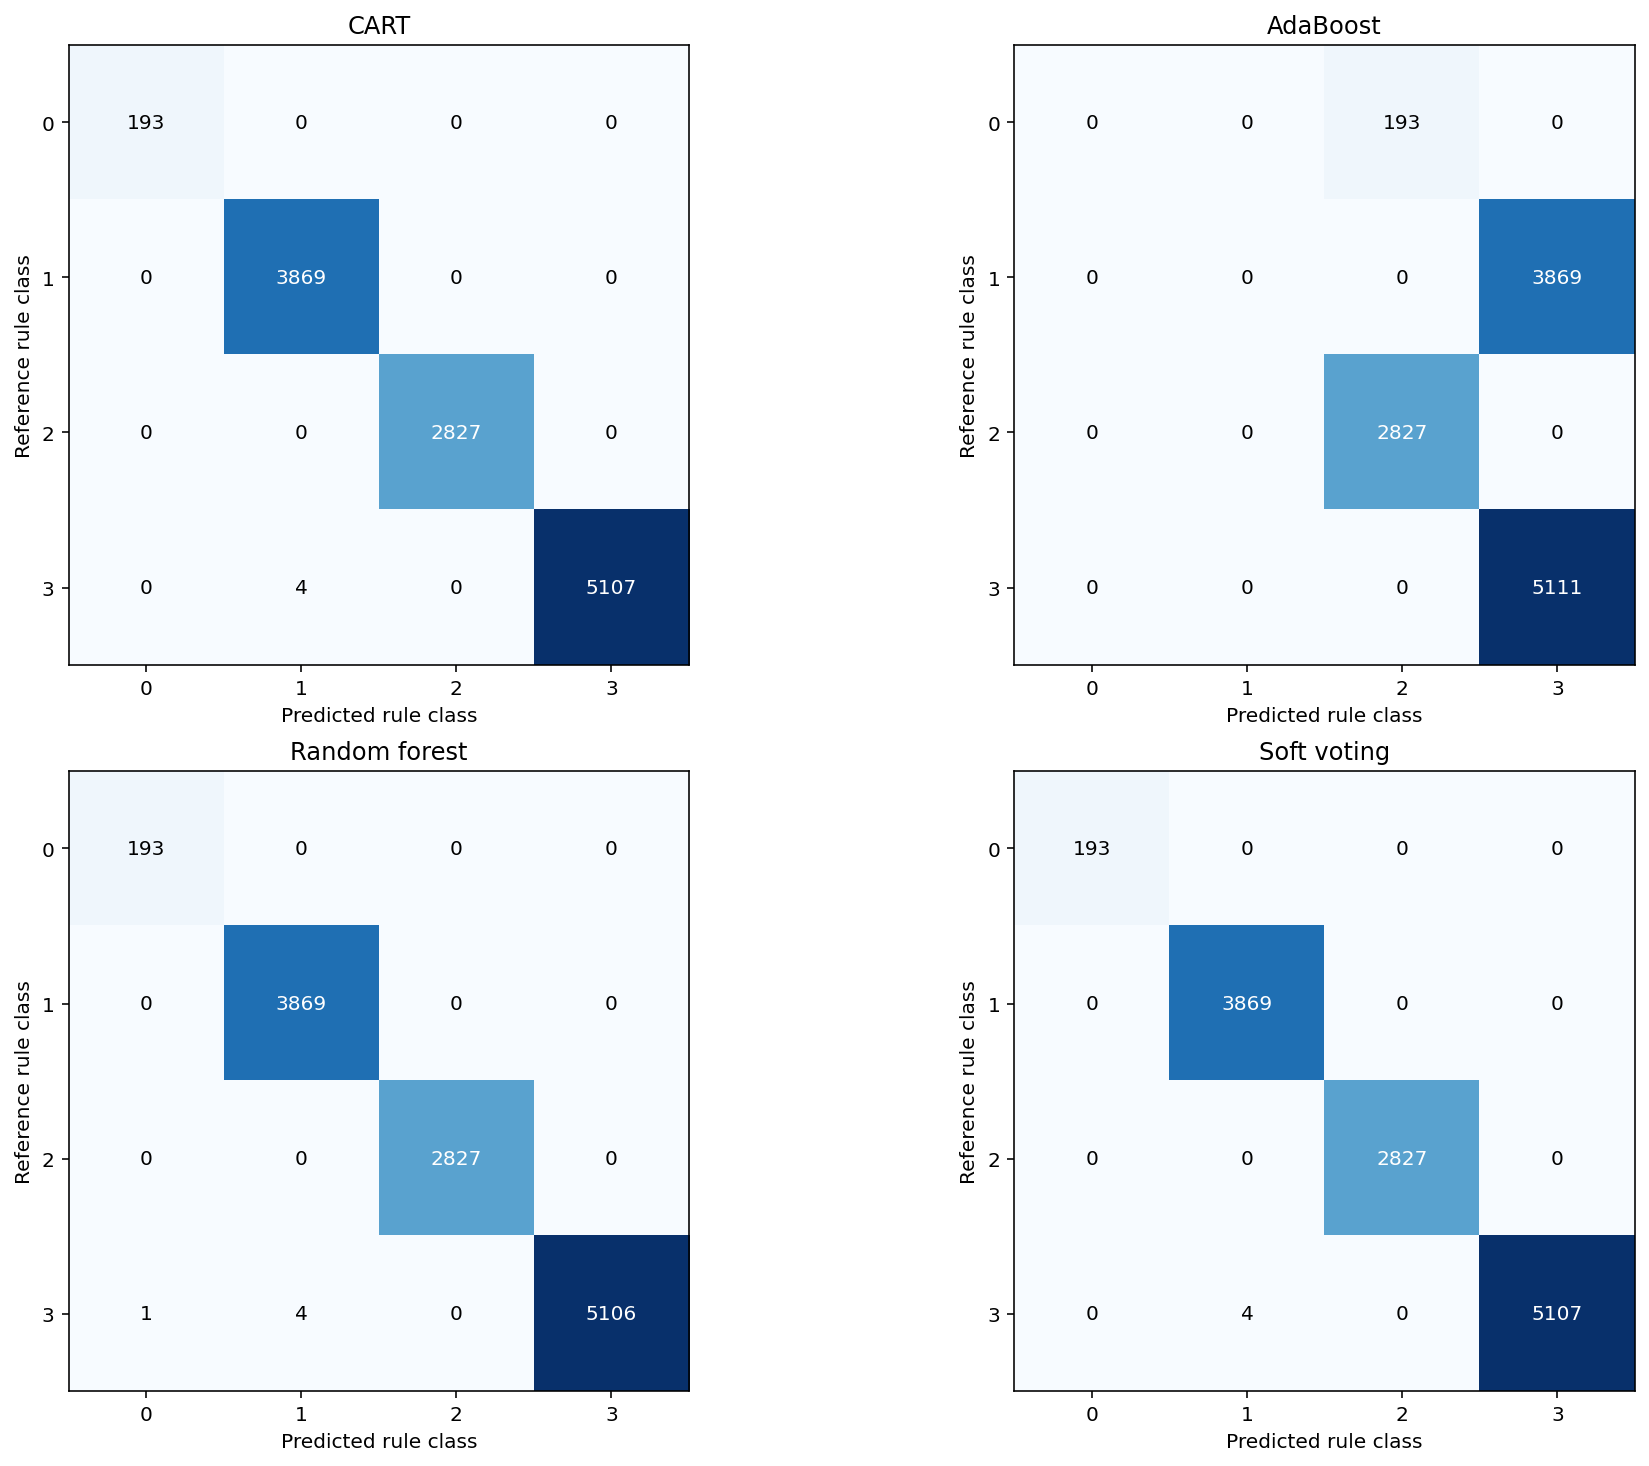

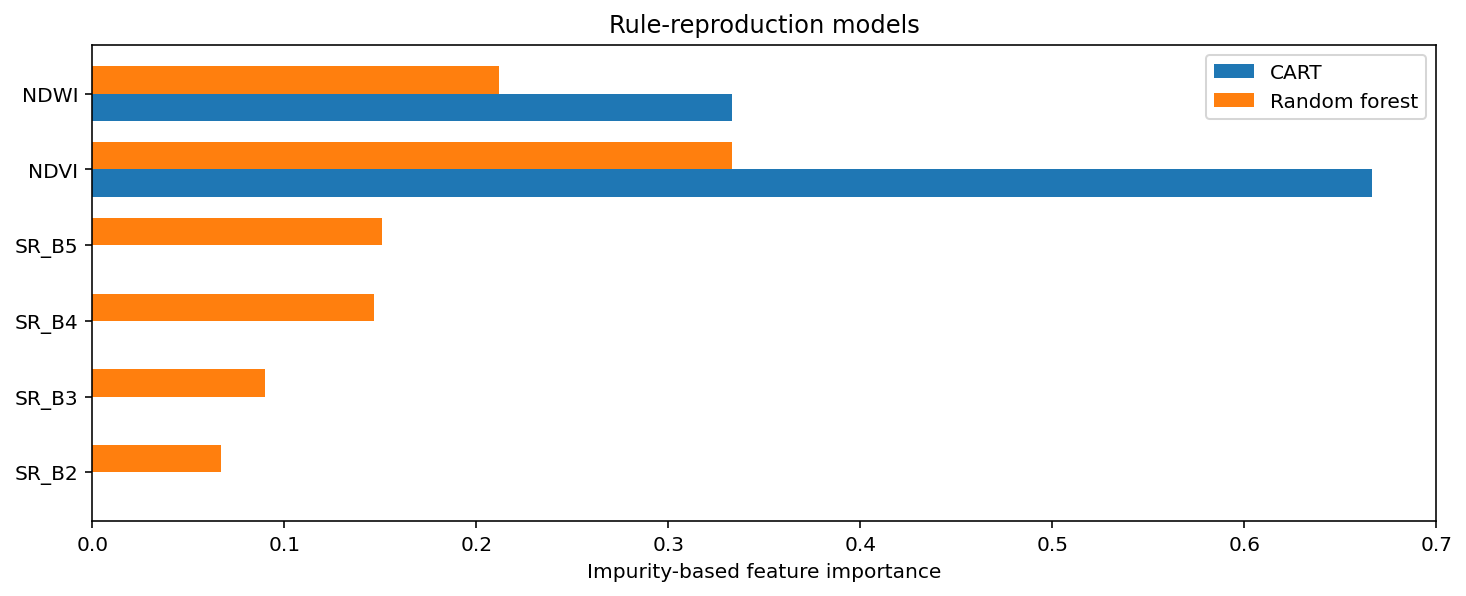

In [8]:
report = save_course_results(data, unsupervised, temporal, supervised, OUTPUT)
for name in ['kmeans_maps.png', 'pca_exploration.png', 'hmm_states.png', 'hmm_change.png',
             'sum_product_transitions.png', 'spatial_split.png', 'cart_tree.png',
             'pbl3_predictions.png', 'model_comparison.png', 'confusion_matrices.png', 'feature_importance.png']:
    display(Image(filename=str(OUTPUT / name), width=850))


## Conclusion and consolidated report

These experiments demonstrate the requested methods on real imagery. Provisional rule agreement
does not validate land-cover classes, seasonal change or urban growth. The HMM posterior depends on
an assumed transition prior. Independent labels, matched seasons, a geographic boundary and additional
acquisitions are needed for stronger conclusions. Run python build_project_report.py after generating
the course results to rebuild the consolidated PDF and editable Markdown report.

References: scikit-learn 1.8 user guides for clustering, PCA, trees and ensembles;
Michael Collins, The Forward-Backward Algorithm; USGS Landsat Collection 2 QA and surface reflectance documentation.
